In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
from numpy.linalg import norm
import datetime
import math
import multiprocess as mp
import time
import pickle
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from scipy.signal import find_peaks
import pyarrow.feather as feather
sys.path.insert(0, "cellular_cycle")
from cell_cycle_death_model import model
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap

from numpy.fft import fft, ifft
from numpy.fft import rfft, rfftfreq

import tqdm

In [2]:
PARAM = pd.read_csv(Path('model_data/parameters.csv'))  # parameter file to use
INIT_CONCS = pd.read_csv(Path('model_data/initial_concentrations.csv'))  # initial concentrations for simulations

TREATMENT = 'LOW'  # set AKT, ERK, and FAK by setting 'ERL' or 'DMSO'
 
CYCDI_CONC = 0
POINTS = 10  # number to divide each condition into, sets the number of points to divide cell cycle

# number of processes to reserve; set to either 10% or 1, whichever is greater
if round(mp.cpu_count()*0.1,0) < 1:
    RES_PROC = 1
else:
    RES_PROC = round(mp.cpu_count()*0.1,0)

PROCESSES = int(mp.cpu_count() - RES_PROC)  # number of pool processes to run at once
SAVEFILES = True  # save files for lyapunov values and mean IMT values
OVERWRITE = False  # Overwrite existing files
VERBOSE = True
SET_JPARAM = False
PARAM_NUM = 2

integrator_options = {
    "rtol": 1e-12,
    "atol": 1e-12
}

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(), 'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
CURDATE = datetime.datetime.now().strftime('%Y%m%d')

t = np.linspace(0, 1000, 1000001)
t_0 = np.linspace(0, 2000, 2000001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 1

# Importing the parameters:

for key in PARAM.keys():
    try:
        if model.parameters[key].value != PARAM[key][0]:
            model.parameters[key].value = PARAM[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [4]:
if SET_JPARAM:
    with open('fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
        frac_prolif_parameters_pso = pickle.load(f)

    frac_prolif_parameters_pso[('cost', 'custom cost populations')] = frac_prolif_parameters_pso[(
    'cost', 'cost population dynamics 0.6 kPa DMSO')] + frac_prolif_parameters_pso[(
    'cost', 'cost population dynamics 4 kPa erlotinib')] + frac_prolif_parameters_pso[(
    'cost', 'cost population dynamics 55 kPa erlotinib')]
    pso_sort_pops = frac_prolif_parameters_pso.sort_values(by=[('cost', 'custom cost populations')])
    new_params = pso_sort_pops['model parameters']
    # Importing the parameters:
    for key in new_params.keys():
        try:
            if model.parameters[key].value != new_params[key].iloc[PARAM_NUM]:
                model.parameters[key].value = new_params[key].iloc[PARAM_NUM]
        except:
            print(key)
    model.parameters['omega'].value = 200

In [5]:
for key in INIT_CONCS.keys():
    try:
        model.parameters[key].value = INIT_CONCS[key][0] / model.parameters['omega'].value
    except:
        print(key)

model.parameters['CycDi_0'].value = CYCDI_CONC

if TREATMENT == 'ERL':
    FAKs = list(np.linspace(0,0.4,51))
    tmp = list(np.linspace(0.4,0.6,51))
    FAKs.extend(tmp[1:])
    tmp = list(np.linspace(0.6,1,51))
    FAKs.extend(tmp[1:])

    AKTs = list(np.linspace(0,0.3,51))
    tmp = list(np.linspace(0.3,0.6,51))
    AKTs.extend(tmp[1:])
    tmp = [0.6]*50
    AKTs.extend(tmp)
    
    ERKs = [0.2]*151
    
elif TREATMENT == 'DMSO':
    FAKs = list(np.linspace(0,0.4,51))
    tmp = list(np.linspace(0.4,0.6,51))
    FAKs.extend(tmp[1:])
    tmp = list(np.linspace(0.6,1,51))
    FAKs.extend(tmp[1:])

    AKTs = list(np.linspace(0,0.6,51))
    tmp = list(np.linspace(0.6,1,51))
    AKTs.extend(tmp[1:])
    tmp = [1]*50
    AKTs.extend(tmp)
    
    ERKs = [1]*151
else:
    FAKs = list(np.linspace(0,0.4,51))
    tmp = list(np.linspace(0.4,0.6,51))
    FAKs.extend(tmp[1:])
    tmp = list(np.linspace(0.6,1,51))
    FAKs.extend(tmp[1:])

    AKTs = list(np.linspace(0,0.3,51))
    tmp = list(np.linspace(0.3,0.6,51))
    AKTs.extend(tmp[1:])
    tmp = [0.6]*50
    AKTs.extend(tmp)
    
    ERKs = [0.1]*151

conds = [(AKT, ERK, FAK) for AKT, ERK, FAK, in zip(AKTs, ERKs, FAKs)]

In [6]:
conds[102]

(0.6, 0.1, 0.616)

In [8]:
def autocorr(time_series: np.ndarray, normalize: bool = True):
    """
    Compute the (biased) autocorrelation sequence for a 1D real signal.
    Returns the autocorrelation from lag = 0 up to lag = N−1.
    
    Parameters
    ----------
    time_series : np.ndarray
        Input 1D signal.
    normalize : bool
        If True, normalize the ACF so that ACF[0] = 1.
    
    Returns
    -------
    acf : np.ndarray
        Autocorrelation values for lags 0, 1, 2, …, N−1.
    """
    N = len(time_series)
    # subtract mean
    x = time_series - np.mean(time_series)
    # full correlation (lags from −(N−1) to +(N−1))
    corr = np.correlate(x, x, mode="full")
    # take second half (lags ≥ 0)
    acorr = corr[N - 1 : ]
    if normalize:
        # Normalize so that acf[0] = 1
        acorr = acorr / acorr[0]
    return acorr

def estimate_period_via_autocorr(time_series: np.ndarray,
                                 dt: float,
                                 min_lag: int = 1,
                                 max_lag: int = None,
                                 plot: bool = False):
    """
    Estimate the dominant period in the time_series using autocorrelation.
    
    Parameters
    ----------
    time_series : np.ndarray
        Input data signal.
    dt : float
        Sampling interval (same time unit as you want period in).
    min_lag : int
        Minimum lag (in samples) to search for a peak (avoid lag = 0).
    max_lag : int or None
        Maximum lag (in samples) up to which to search for peaks.
        If None, uses up to N−1.
    plot : bool
        If True, plots the autocorrelation and the chosen peak.
    
    Returns
    -------
    best_period : float or None
        The estimated period in same time units as dt (i.e. period = lag × dt).
        Returns None if no suitable peak is found.
    best_lag : int
        The lag (in samples) corresponding to the best peak.
    acf : np.ndarray
        The full autocorrelation array (lags 0 to N−1, normalized).
    """
    N = len(time_series)
    acf = autocorr(time_series, normalize=True)
    
    if max_lag is None:
        max_lag = N - 1
    else:
        max_lag = min(max_lag, N - 1)
    
    # Exclude lag = 0 (which is always the maximal autocorrelation)

    search_region = acf[min_lag : max_lag + 1]
    # In that region, find the index of the peak
    local_index = np.argmax(search_region)
    best_lag = local_index + min_lag
    
    best_period = best_lag * dt
    
    # (Optional) If the peak is too weak (e.g. < some threshold), you might treat as no reliable period
    
    if plot:
        lags = np.arange(len(acf))
        plt.figure(figsize=(8,4))
        plt.plot(lags * dt, acf, label="ACF")
        plt.axvline(best_period, color='r', ls='--',
                    label=f"Peak at lag = {best_lag}, period = {best_period:.3g}")
        plt.xlabel("Lag (time units)")
        plt.ylabel("Autocorrelation (normalized)")
        plt.legend()
        plt.grid(True)
        plt.show()
    
    return best_period, best_lag, acf

In [7]:
def run_lyaps(AKT, ERK, FAK, np=np, model=model, points=POINTS, ScipyOdeSimulator=ScipyOdeSimulator,
              find_peaks=find_peaks, integrator_options=integrator_options, norm=norm, math=math,
              verbose=VERBOSE):
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    ep = 0.001 * 200
    t = np.linspace(0, 1000, 1000001)
    t_0 = np.linspace(0, 2000, 2000001)
    all_logz = dict.fromkeys(list(range(1, points + 1)))

    for kk in range(points):
        sim_ode = ScipyOdeSimulator(model, t_0, verbose=False, compiler='python',
                                    integrator_options=integrator_options).run()
        y_out = sim_ode.observables

        peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence=0.6, distance=10)
        # new_y = y_out[peaks_cdc[-11]:peaks_cdc[-2]]
        peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]
        peaks_half2 = peaks_cdc[peaks_cdc > len(y_out) / 2]

        if len(peaks_half2) > 3:
            IMTs = [t_0[y] - t_0[x] for x, y in zip(peaks_half2, peaks_half2[1:])]
            meanIMT = sum(IMTs) / len(IMTs)
            variable_range = y_out[peaks_half[-3]:peaks_half[-2]]
            tmp_loc = (round(len(variable_range) / (points)) * (kk))
        else:
            meanIMT = 0
            variable_range = y_out[575000:600000]
            tmp_loc = (round(len(variable_range) / (points)) * (kk))
        if verbose:
            print(meanIMT)


        Initial_1 = variable_range[tmp_loc]
        Initial_1 = [val + ep for val in Initial_1]

        prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
                 'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
                 'Cdc20_0']
        prot_init = {prots[i]: Initial_1[i] for i in range(len(prots))}

        for key in prot_init.keys():
            model.parameters[key].value = prot_init[key] / model.parameters['omega'].value

        sim_ode1 = ScipyOdeSimulator(model, t, verbose=False, compiler='python',
                                     integrator_options=integrator_options).run()
        y_out1 = sim_ode1.observables

        z = [0] * (round((len(y_out1) / 2000)) + 1)
        n = 0
        for i in range(0, len(y_out1), 2000):
            if len(peaks_half2) > 0:
                window = y_out[peaks_half[-3]+i+tmp_loc-5000:peaks_half[-2]+i+tmp_loc+5000]
            else:
                window = y_out[575000+i+tmp_loc-5000:600000+i+tmp_loc+5000]

            dists = [0] * len(window)
            for j in range(0, len(window)):
                dif = np.asarray(window[j].tolist())-np.asarray(y_out1[i].tolist())
                dists[j] = norm(dif[0:19]/200)

            z[n] = min(dists)
            n = n + 1

        logz = [math.log(num) for num in z]
        all_logz[kk + 1] = logz
        if verbose:
            print([AKT, ERK, FAK, kk])

    return all_logz, meanIMT

In [8]:
def pdm_period(x, dt, pmin, pmax, n_periods=2000, n_phase_bins=20, min_points_per_bin=5,
               prefer_fundamental=True, harmonic_check=(2,3,4)):
    """
    Phase Dispersion Minimization (Stellingwerf '78).
    Works for non-sinusoids and multi-peak cycles.

    Parameters
    ----------
    x : 1D array
        Time series (evenly sampled).
    dt : float
        Sample interval (time units of your choice).
    pmin, pmax : float
        Period search bounds (same units as dt).
    n_periods : int
        Number of trial periods between [pmin, pmax].
    n_phase_bins : int
        Number of bins for folding.
    min_points_per_bin : int
        Require at least this many points per bin; otherwise skip that period.
    prefer_fundamental : bool
        If True, apply harmonic sieve to prefer larger (fundamental) periods.
    harmonic_check : tuple
        Integers k to check (k*P). If the score is similarly good at multiples,
        pick the *largest* P among the set.

    Returns
    -------
    best_P : float
        Estimated period.
    periods : (n,) array
        Trial periods.
    theta : (n,) array
        PDM theta statistic (lower is better).
    """
    x = np.asarray(x, float)
    N = len(x)
    t = np.arange(N) * dt
    x = x - np.mean(x)

    periods = np.linspace(pmin, pmax, n_periods)
    theta = np.full_like(periods, np.nan, dtype=float)

    # Global variance
    s2 = np.var(x, ddof=1)

    for i, P in enumerate(periods):
        # Need enough cycles to say anything
        if (N*dt)/P < 3:
            continue

        phase = (t % P) / P
        order = np.argsort(phase)
        phase_sorted = phase[order]
        x_sorted = x[order]

        # bin edges and indices
        bins = np.linspace(0.0, 1.0, n_phase_bins+1)
        idx = np.digitize(phase_sorted, bins) - 1  # 0..n_bins-1

        # compute within-bin variance
        num = 0.0
        den = 0
        ok = True
        for b in range(n_phase_bins):
            mask = (idx == b)
            nb = np.sum(mask)
            if nb < min_points_per_bin:
                ok = False
                break
            xb = x_sorted[mask]
            num += (nb - 1) * np.var(xb, ddof=1)
            den += (nb - 1)
        if not ok or den == 0 or s2 == 0:
            continue

        # Stellingwerf theta: ratio of binned variance to global variance
        theta[i] = num / (den * s2)

    # lower theta is better
    valid = np.isfinite(theta)
    if not np.any(valid):
        return np.nan, periods, theta

    idx_best = np.nanargmin(theta)
    best_P = periods[idx_best]

    if prefer_fundamental:
        # If k*P has similarly low theta, choose the largest such P (the fundamental)
        best_set = [(best_P, theta[idx_best])]
        for k in harmonic_check:
            Pk = best_P * k
            if Pk > pmax:
                break
            # find closest trial period
            j = np.abs(periods - Pk).argmin()
            if np.isfinite(theta[j]):
                best_set.append((periods[j], theta[j]))
        # pick the P with the lowest theta among these,
        # then if several are within ~5% of the minimum, choose the *largest* period
        vals = np.array([th for _, th in best_set])
        Pvals = np.array([P for P, _ in best_set])
        th_min = vals.min()
        near = Pvals[vals <= th_min * 1.05]       # within 5% of the minimum
        if len(near) > 0:
            best_P = near.max()                   # favor the fundamental

    return best_P, periods, theta


In [9]:
def pca_first_component(X):
    # X: (n_species, T), z-scored per species already
    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    pc1 = Vt[0]          # shape (T,)
    return pc1

In [10]:
AKT = 1
ERK = 1
FAK = 1
model.parameters['AKT'].value = AKT
model.parameters['ERK'].value = ERK
model.parameters['FAK'].value = FAK
points = 10
verbose = True
# ep = 0.001 * 200
ep = 0.001
t = np.linspace(0, 1000, 1000001)
t_0 = np.linspace(0, 2000, 2000001)
dt = t[1]-t[0]
all_logz = dict.fromkeys(list(range(1, points + 1)))

In [11]:
kk = 0
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python',
                            integrator_options=integrator_options).run()
y_out = sim_ode.observables

peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence=0.6, distance=10)
# new_y = y_out[peaks_cdc[-11]:peaks_cdc[-2]]
peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]
peaks_half2 = peaks_cdc[peaks_cdc > len(y_out) / 2]
names = y_out.dtype.names  

In [12]:
if len(peaks_half2) > 3:
    IMTs = [t[y] - t[x] for x, y in zip(peaks_half2, peaks_half2[1:])]
    meanIMT = sum(IMTs) / len(IMTs)
    stdIMT = np.std(IMTs)
    tmp_range = y_out[peaks_half2[-3]:peaks_half2[-2]]
    ref_cycle = np.column_stack([tmp_range[n] for n in names[:19]])
    t_slice = t[peaks_half[-3]:peaks_half[-2]]
    tmp_loc = (round(len(tmp_range) / (points)) * (kk))
else:
    meanIMT = 0
    tmp_range = y_out[575000:600000]
    ref_cycle = np.column_stack([tmp_range[n] for n in names[:19]])
    tmp_loc = (round(len(tmp_range) / (points)) * (kk))
    t_slice = t[575000:600000]
if verbose:
    print(meanIMT)

22.124714285714287


In [13]:
def finite_diff_loop(arr, t):
    """
    Finite difference for one-period template (shape: (M,d)).
    Handles non-uniform time spacing and enforces periodic wrap.

    Parameters
    ----------
    arr : ndarray, shape (M,d)
        One-period trajectory samples.
    t : ndarray, shape (M,)
        Corresponding times or phases (need not be uniform).

    Returns
    -------
    darr : ndarray, shape (M,d)
        Estimated derivatives at each point.
    """
    arr = np.asarray(arr, dtype=float)
    t = np.asarray(t, dtype=float)
    M, d = arr.shape
    darr = np.zeros_like(arr)

    # interior points: np.gradient handles non-uniform t
    for j in range(d):
        darr[:, j] = np.gradient(arr[:, j], t)

    # periodic wrap: replace first/last rows with central diff across boundary
    dt0 = (t[1] - t[0]) + (t[-1] - t[-2])  # average step near edges
    darr[0]  = (arr[1] - arr[-1]) / (t[1] - t[-1] + (t[-1]-t[0]))
    darr[-1] = (arr[0] - arr[-2]) / (t[0] - t[-2] + (t[-1]-t[0]))

    return darr


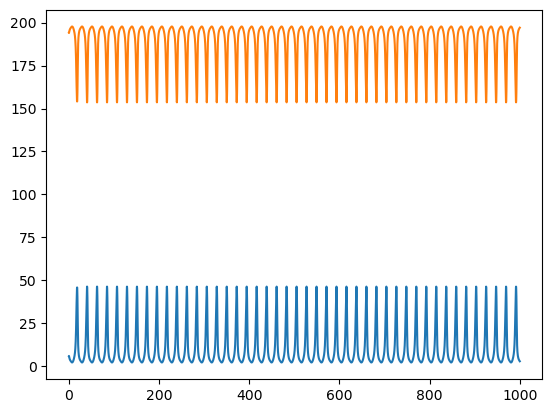

In [14]:
# plt.plot(ref_dcycle[:, 18])
# plt.plot(t[:200],y_out['obsCycE'][:200])
plt.plot(t,y_out['obscdh1act'])
plt.plot(t,y_out['obscdh1inact'])

In [16]:
rs = 1/3.6 #sampling rate
ts = 3.6  #sampling interval (seconds, 0.1 hours)


In [15]:
tmp_range = y_out[peaks_half2[0]:peaks_half2[-1]]
range2 = np.column_stack([tmp_range[n] for n in names[:19]])
t1 = np.arange(0,0.001*len(tmp_range),0.001)

In [16]:
def one_sided_fft(
    time_series: np.ndarray,
    dt: float,
    window: str = "hann",
    normalize: bool = True
):
    """
    Compute a one-sided FFT of a real-valued time series with optional windowing.
    
    Parameters
    ----------
    time_series : np.ndarray
        1D real-valued signal samples.
    dt : float
        Sampling interval (in hours, seconds, or whatever time unit your data uses).
    window : str or None
        Type of window to apply before FFT. Options: "hann", "hamming", "blackman",
        "rect" (or None for no window). Default is "hann".
    normalize : bool
        If True, scale the output amplitude so that it approximates the real
        signal amplitude (i.e. multiply by 2/N etc.). If False, returns raw |FFT|.
    
    Returns
    -------
    freqs : np.ndarray
        1D array of nonnegative frequencies (0 up to Nyquist), in cycles per unit time (1 / time unit of dt).
    amplitude : np.ndarray
        The one-sided amplitude spectrum (magnitude) (same length as freqs).
    phase : np.ndarray
        Phase of the corresponding frequency components (in radians).
    """
    # Number of samples
    N = len(time_series)
    if N < 1:
        raise ValueError("time_series must have at least one sample")
    
    # Choose window
    if window is None or window.lower() in ("rect", "none"):
        w = np.ones(N)
    elif window.lower() == "hann":
        w = np.hanning(N)
    elif window.lower() == "hamming":
        w = np.hamming(N)
    elif window.lower() == "blackman":
        w = np.blackman(N)
    else:
        raise ValueError(f"Unsupported window type: {window}")
    
    # Apply window
    xw = time_series * w
    
    # Compute real FFT (gives only nonnegative freqs)  
    fft_vals = np.fft.rfft(xw)
    freqs = np.fft.rfftfreq(N, d=dt)  # frequencies corresponding to rfft output :contentReference[oaicite:0]{index=0}
    
    # Magnitude and phase
    amp = np.abs(fft_vals)
    ph = np.angle(fft_vals)
    
    if normalize:
        # The standard scaling: multiply non-DC, non-Nyquist bins by 2/N
        # DC (freq = 0) usually not doubled. If N is even, the Nyquist bin (last bin) also not doubled.
        # A simpler approach: multiply entire spectrum by (2 / N), then correct DC & Nyquist if necessary.
        scale = 2.0 / N
        amp = amp * scale
        
        # But correct DC component (freq = 0) — it should not be doubled from the negative side
        amp[0] = amp[0] / 2.0  # remove the extra doubling for DC
        
        # If N is even, the last frequency is Nyquist (freq = 1/(2 dt)), which should not be doubled
        if N % 2 == 0:
            amp[-1] = amp[-1] / 2.0
    
    return freqs, amp, ph

def find_dominant_frequency(freqs: np.ndarray, amplitude: np.ndarray):
    """
    Given the one-sided frequency array and amplitude spectrum,
    return the frequency (nonzero) with highest amplitude and its amplitude.
    
    Parameters
    ----------
    freqs : np.ndarray
        Frequencies returned by rfftfreq (nonnegative, one-sided).
    amplitude : np.ndarray
        Corresponding amplitude magnitudes (one-sided, normalized).
    
    Returns
    -------
    dominant_freq : float
        Frequency (in same units as freqs) of the largest non-zero amplitude bin.
    dominant_amp : float
        The amplitude at that frequency.
    dominant_idx : int
        The index into freqs / amplitude for that bin.
    """
    # Exclude the zero frequency (DC) bin at index 0
    # so only look at indices >= 1.
    if len(freqs) < 2:
        raise ValueError("Need at least two frequency bins to find non-zero dominant frequency")
    
    # Search only among indices 1 through end
    idx = np.argmax(amplitude[1:]) + 1  # +1 because we skipped zero
    dom_freq = freqs[idx]
    dom_amp = amplitude[idx]
    return dom_freq, dom_amp, idx

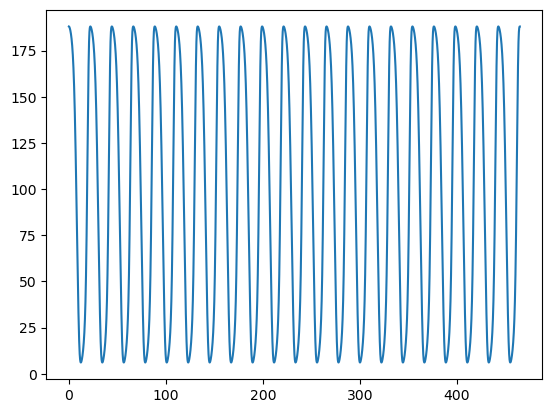

In [19]:
plt.plot(t1, range2[:, 18])


In [20]:
freqs, amplitude, phase = one_sided_fft(range2[:, 18], 0.001, window="hann", normalize=False)

In [21]:
dom_freq, dom_amp, dom_idx = find_dominant_frequency(freqs, amplitude)

In [22]:
1/dom_freq

22.124714285714287

In [38]:
test = pca_first_component(range2)

In [26]:
Pmin, Pmax = 18, 100
P_pdm, Ps, thetas = pdm_period(range2[:, 18], 0.001, Pmin, Pmax, n_periods=3000, n_phase_bins=24)

print("PDM period:", P_pdm, "hours")

PDM period: 22.128709569856618 hours


(0.0, 0.4)

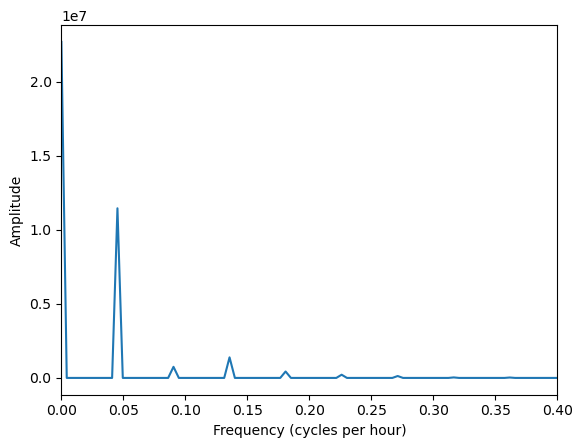

In [27]:
plt.plot(freqs, amplitude, "-")
plt.xlabel("Frequency (cycles per hour)")
plt.ylabel("Amplitude")

plt.xlim(0, 0.4)

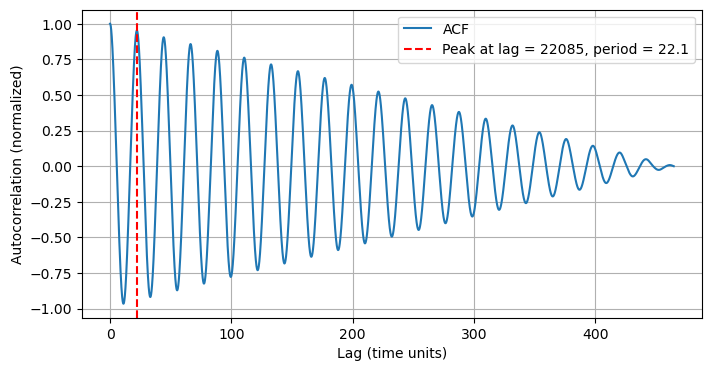

In [28]:
est_period, est_lag, acf = estimate_period_via_autocorr(range2[:, 18], 0.001, min_lag=10000, plot=True)


In [29]:
est_period

22.085

In [123]:
AKT = 1
ERK = 1
FAK = 0.6
model.parameters['AKT'].value = AKT
model.parameters['ERK'].value = ERK
model.parameters['FAK'].value = FAK
points = 10
verbose = True
# ep = 0.001 * 200
ep = 0.001
t = np.linspace(0, 1000, 1000001)
t_0 = np.linspace(0, 2000, 2000001)
dt = t[1]-t[0]
all_logz = dict.fromkeys(list(range(1, points + 1)))

In [141]:
kk = 0
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python',
                            integrator_options=integrator_options).run()
y_out = sim_ode.observables

peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence=0.6, distance=10)
# new_y = y_out[peaks_cdc[-11]:peaks_cdc[-2]]
peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]
peaks_half2 = peaks_cdc[peaks_cdc > len(y_out) / 2]
names = y_out.dtype.names  

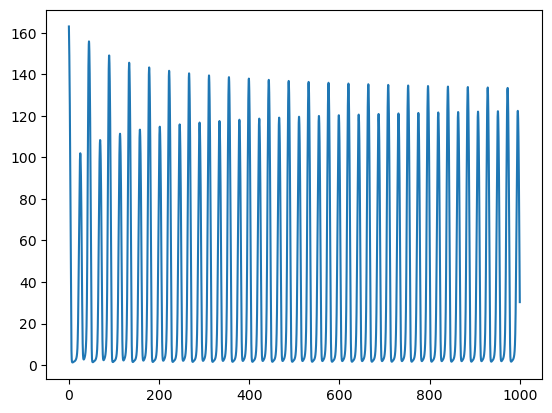

In [142]:
plt.plot(t,y_out['obsCycE'])

In [143]:
tmp_range = y_out[peaks_half2[0]:peaks_half2[-1]]
range2 = np.column_stack([tmp_range[n] for n in names[:19]])
t1 = np.arange(0,0.001*len(tmp_range),0.001)

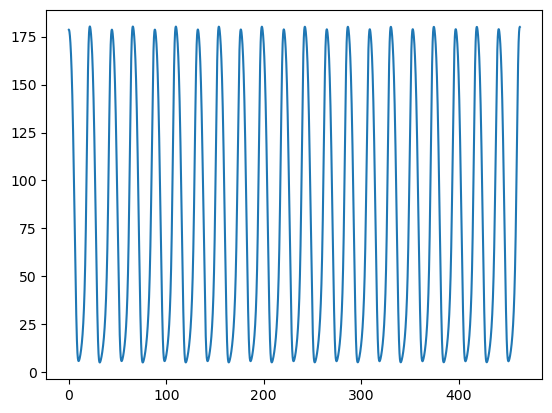

In [144]:
plt.plot(t1, range2[:, 18])

In [17]:
def yin_period(x, dt, pmin=None, pmax=None, thresh=0.1):
    """
    YIN period estimator (robust to subharmonics / every-other-peak errors)
    Parameters
    ----------
    x : 1D array
        Time series data.
    dt : float
        Sampling interval (same time unit as period result).
    pmin, pmax : float
        Optional bounds on period (same units as dt).
    thresh : float
        Threshold for cumulative normalized difference (typical 0.05–0.2).

    Returns
    -------
    period : float or np.nan
        Estimated period (same units as dt).
    """
    x = np.asarray(x, dtype=float)
    x = x - np.mean(x)
    N = len(x)
    if N < 3:
        return np.nan

    if pmin is None: pmin = 2 * dt
    if pmax is None: pmax = N / 2 * dt

    tau_min = int(np.floor(pmin / dt))
    tau_max = int(np.ceil(pmax / dt))
    tau_max = min(tau_max, N // 2)
    if tau_max <= tau_min:
        return np.nan

    # Difference function
    d = np.zeros(tau_max + 1)
    for tau in range(1, tau_max + 1):
        diff = x[:-tau] - x[tau:]
        d[tau] = np.sum(diff * diff)

    # Cumulative mean normalized difference
    cmndf = np.zeros_like(d)
    cmndf[0] = 1
    running_sum = np.cumsum(d[1:tau_max + 1])
    cmndf[1:tau_max + 1] = d[1:tau_max + 1] * np.arange(1, tau_max + 1) / (running_sum + 1e-12)

    # Threshold crossing
    candidates = np.where(cmndf[tau_min:] < thresh)[0]
    if len(candidates) == 0:
        tau = np.argmin(cmndf[tau_min:]) + tau_min
    else:
        tau = candidates[0] + tau_min

    # Parabolic refinement for sub-sample precision
    if 1 < tau < tau_max:
        y1, y2, y3 = cmndf[tau - 1], cmndf[tau], cmndf[tau + 1]
        denom = y1 - 2 * y2 + y3
        if abs(denom) > 1e-12:
            tau = tau + 0.5 * (y1 - y3) / denom

    return tau * dt


# ==========================================================
# 2. Autocorrelation and Mean ACF period
# ==========================================================

def autocorr_1d(x, normalize=True):
    """Compute 1D autocorrelation for a single signal."""
    x = np.asarray(x, float)
    x -= np.mean(x)
    result = np.correlate(x, x, mode="full")[len(x)-1:]
    if normalize:
        result /= (result[0] + 1e-12)
    return result

def mean_acf_period(X, dt, min_lag=1, max_lag=None, plot=False):
    """
    Compute mean autocorrelation across species and estimate dominant period.

    Parameters
    ----------
    X : array (n_species, n_timepoints)
    dt : float
        Sampling interval.
    min_lag, max_lag : int
        Search window for period.
    plot : bool
        If True, plots mean ACF and detected period.

    Returns
    -------
    period : float
    mean_acf : np.ndarray
    """
    n, T = X.shape
    acfs = []
    for i in range(n):
        xi = (X[i] - np.mean(X[i])) / (np.std(X[i]) + 1e-12)
        acfs.append(autocorr_1d(xi))
    mean_acf = np.mean(acfs, axis=0)

    if max_lag is None:
        max_lag = T - 1
    j0 = max(min_lag, 1)
    j = j0 + np.argmax(mean_acf[j0:max_lag + 1])
    period = j * dt

    if plot:
        lags = np.arange(len(mean_acf)) * dt
        plt.figure(figsize=(7,4))
        plt.plot(lags, mean_acf, label='Mean ACF')
        plt.axvline(period, color='r', ls='--', label=f'Period = {period:.3f}')
        plt.xlabel("Lag (time units)")
        plt.ylabel("Autocorrelation")
        plt.legend()
        plt.grid(True)
        plt.show()

    return period, mean_acf


# ==========================================================
# 3. PCA first component & YIN combo
# ==========================================================

def pca_first_component_timecourse(X, standardize="row"):
    """
    Return the first principal component *time course* (length T).
    
    Parameters
    ----------
    X : array, shape (n_species, T)
        Rows are species/variables, columns are timepoints.
    standardize : {"row", "none"}
        "row": z-score each species (row) across time before PCA.
        "none": use raw values.

    Returns
    -------
    pc1_t : array, shape (T,)
        First PC scores over time (principal time course).
    loadings : array, shape (n_species,)
        PC1 loadings across species (how each species contributes).
    """
    X = np.asarray(X, float)
    n, T = X.shape

    if standardize == "row":
        Xz = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 1e-12)
    elif standardize == "none":
        Xz = X
    else:
        raise ValueError("standardize must be 'row' or 'none'")

    # SVD on (T x n_species): timepoints = observations
    # Xz.T = U (T x r) @ np.diag(S) (r x r) @ Vt (r x n_species)
    U, S, Vt = np.linalg.svd(Xz.T, full_matrices=False)

    # PC1 time series (scores for each timepoint)
    pc1_t = U[:, 0] * S[0]               # length T

    # PC1 loadings across species (how species align with PC1)
    loadings = Vt[0]                     # length n_species

    return pc1_t, loadings

def period_pca_yin(X, dt, pmin=None, pmax=None, thresh=0.1):
    """
    Use PCA to get the consensus oscillatory time course, then estimate
    its period via YIN (robust to half-period errors).
    """
    pc1_t, _ = pca_first_component_timecourse(X, standardize="row")
    period = yin_period(pc1_t, dt, pmin=pmin, pmax=pmax, thresh=thresh)
    return period, pc1_t


# ==========================================================
# 4. Averaged Power Spectrum (frequency domain)
# ==========================================================

def period_avg_spectrum(X, dt, plot=False):
    """
    Average power spectra across species and find dominant period.
    """
    n, T = X.shape
    all_ps = []
    for i in range(n):
        xi = (X[i] - np.mean(X[i])) / (np.std(X[i]) + 1e-12)
        Xi = np.abs(rfft(xi))**2
        all_ps.append(Xi)
    Pmean = np.mean(all_ps, axis=0)
    freqs = rfftfreq(T, d=dt)

    idx = np.argmax(Pmean[1:]) + 1  # skip DC
    f0 = freqs[idx]
    period = 1.0 / f0 if f0 > 0 else np.nan

    if plot:
        plt.figure(figsize=(7,4))
        plt.plot(freqs, Pmean, label='Mean Power Spectrum')
        plt.axvline(f0, color='r', ls='--', label=f'f0 = {f0:.3f} (1/unit)')
        plt.xlabel("Frequency (1 / time units)")
        plt.ylabel("Power")
        plt.legend()
        plt.grid(True)
        plt.show()

    return period, freqs, Pmean


# ==========================================================
# 5. Unified wrapper
# ==========================================================

def analyze_multi_species_periods(X, dt, pmin=None, pmax=None, plot=True):
    """
    Runs three complementary analyses:
      1. Mean autocorrelation period
      2. PCA + YIN period
      3. Mean power spectrum period
    Returns a dict with results.
    """
    results = {}

    p_acf, mean_acf = mean_acf_period(X, dt, plot=plot)
    p_pca, pc1 = period_pca_yin(X, dt, pmin=pmin, pmax=pmax)
    p_spec, freqs, Pmean = period_avg_spectrum(X, dt, plot=plot)

    results["mean_acf_period"] = p_acf
    results["pca_yin_period"] = p_pca
    results["spectrum_period"] = p_spec
    results["mean_acf"] = mean_acf
    results["pca_signal"] = pc1
    results["freqs"] = freqs
    results["mean_power"] = Pmean

    if plot:
        print(f"Mean ACF period: {p_acf:.4f}")
        print(f"PCA + YIN period: {p_pca:.4f}")
        print(f"Spectral period: {p_spec:.4f}")

    return results

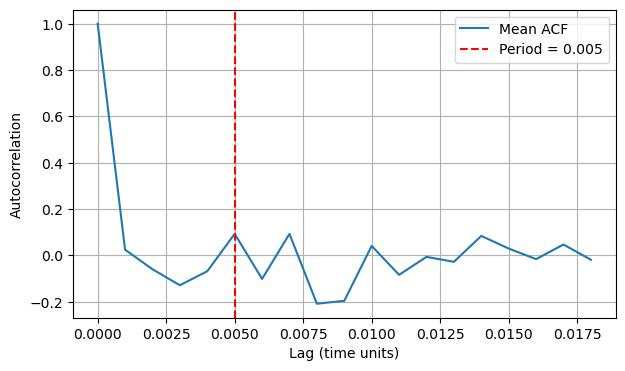

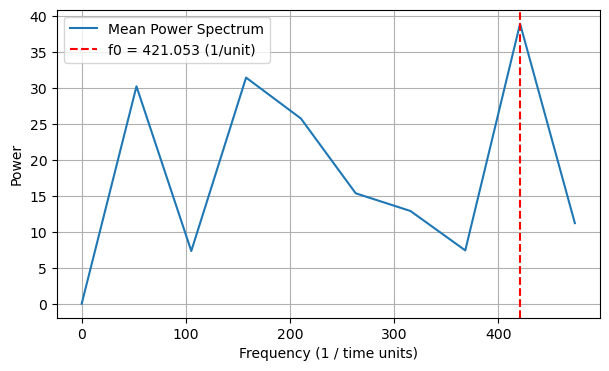

Mean ACF period: 0.0050
PCA + YIN period: nan
Spectral period: 0.0024


In [63]:
results = analyze_multi_species_periods(range2, 0.001, pmin=15, pmax=200)

In [80]:
p_pca, pc1 = period_pca_yin(range2, 0.001, pmin=15, pmax=200)

In [81]:
pc1

array([-517.60527349, -289.44069327, -321.99885249, -233.41927464,
       1256.57585701,  955.18516848, -107.60952482, -422.15806682,
       -151.84836101, 1075.11690068, -125.67619304,  293.81614014,
       -207.48306453, -588.16501321,    5.98925703, -466.77278254,
         63.97695474, -548.12664378,  329.64346556])

In [82]:
freqs, amplitude, phase = one_sided_fft(range2[:, 18], 0.001, window="hann", normalize=False)
dom_freq, dom_amp, dom_idx = find_dominant_frequency(freqs, amplitude)

In [36]:
Pmin, Pmax = 18, 100
P_pdm, Ps, thetas = pdm_period(range2[:, 18], 0.001, Pmin, Pmax, n_periods=3000, n_phase_bins=24)

print("PDM period:", P_pdm, "hours")

PDM period: 22.046682227409136 hours


(0.0, 0.4)

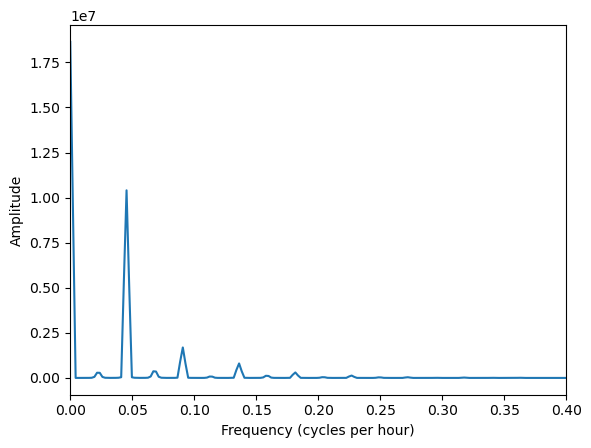

In [53]:
plt.plot(freqs, amplitude, "-")
plt.xlabel("Frequency (cycles per hour)")
plt.ylabel("Amplitude")

plt.xlim(0, 0.4)

In [83]:
1/dom_freq

22.036809523809527

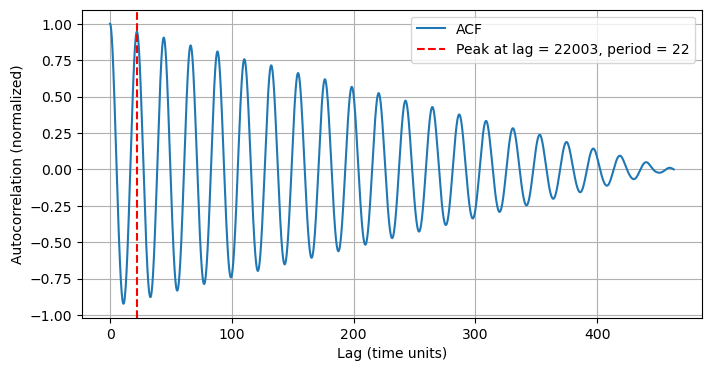

In [84]:
est_period, est_lag, acf = estimate_period_via_autocorr(range2[:, 18], 0.001, min_lag=10000, plot=True)

In [18]:
def sliding_window_autocorr(x, dt, window_size, step_size=None, max_lag=None, normalize=True):
    """
    Compute short-time (windowed) autocorrelation of a 1D time series.

    Parameters
    ----------
    x : 1D array
        Time series.
    dt : float
        Sampling interval.
    window_size : int
        Window length in samples.
    step_size : int or None
        Step between successive windows (samples). If None, defaults to window_size/4.
    max_lag : int or None
        Maximum lag to compute (samples). If None, defaults to window_size/2.
    normalize : bool
        If True, normalize each window's autocorrelation to have ACF(0) = 1.

    Returns
    -------
    acf_matrix : 2D array [n_windows, max_lag]
        Short-time autocorrelation for each window.
    lag_times : 1D array
        Lag axis in time units.
    window_centers : 1D array
        Time (center of each window) axis.
    """
    x = np.asarray(x, float)
    N = len(x)
    if step_size is None:
        step_size = window_size // 4
    if max_lag is None:
        max_lag = window_size // 2

    n_windows = (N - window_size) // step_size + 1
    acf_matrix = np.zeros((n_windows, max_lag))

    for i in range(n_windows):
        start = i * step_size
        end = start + window_size
        seg = x[start:end]
        seg -= np.mean(seg)
        acf = np.correlate(seg, seg, mode='full')[window_size-1:]
        acf = acf[:max_lag]
        if normalize:
            acf /= (acf[0] + 1e-12)
        acf_matrix[i, :] = acf

    window_centers = (np.arange(n_windows) * step_size + window_size/2) * dt
    lag_times = np.arange(max_lag) * dt

    return acf_matrix, lag_times, window_centers

In [151]:
test = np.copy(range2[:, 12])

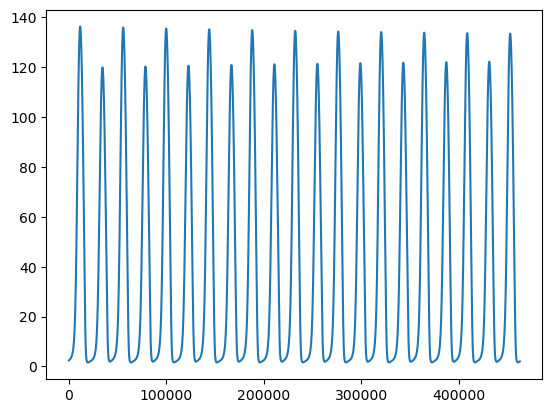

In [152]:
plt.plot(test)

In [147]:
acf_mat, lags, centers = sliding_window_autocorr(test, 0.001, window_size=1000, step_size=500)

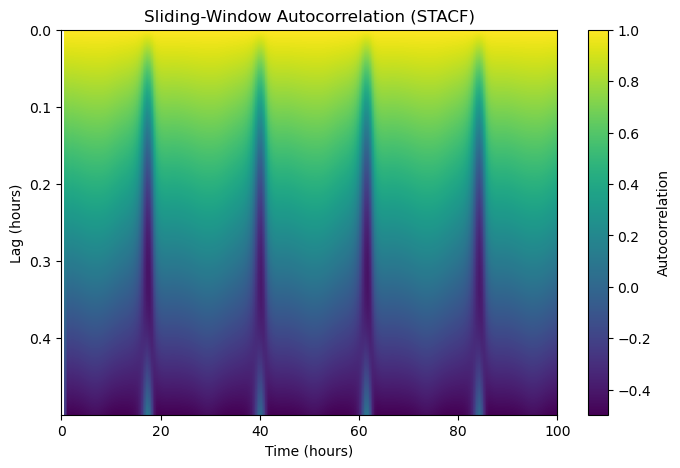

In [148]:
plt.figure(figsize=(8,5))
plt.xlim(0,100)
plt.imshow(acf_mat.T, extent=[centers[0], centers[-1], lags[-1], lags[0]],
           aspect='auto', cmap='viridis')
plt.colorbar(label='Autocorrelation')
plt.xlabel('Time (hours)')
plt.ylabel('Lag (hours)')
plt.title('Sliding-Window Autocorrelation (STACF)')
plt.show()


In [19]:
def transverse_distance_series(x_traj, ref_cycle, ref_dcycle):
    # dense grid of phases
    M = ref_cycle.shape[0]
    rs = []
    for x in x_traj:
        # phase alignment: nearest point on reference cycle
        j = np.argmin(np.linalg.norm(ref_cycle - x, axis=1))
        v = ref_dcycle[j]
        vhat = v / (np.linalg.norm(v) + 1e-12)
        d = x - ref_cycle[j]
        d_perp = d - np.dot(d, vhat) * vhat
        rs.append(np.linalg.norm(d_perp))
    return np.array(rs)

def perturb_orthogonal_nonneg(
    x19, ref_cycle, ref_dcycle,
    magnitude=1e-3,     # preferred absolute perturbation size
    safety=0.9,         # back off a bit from the hard bound
    rng=None
):
    """
    Add a perturbation to x19 in a direction orthogonal to the cycle tangent,
    with preferred absolute size 'magnitude', while ensuring all components
    remain nonnegative.

    Parameters
    ----------
    x19 : (d,) array
        Current state (must be nonnegative).
    ref_cycle : (M,d) array
        One-period template trajectory.
    ref_dcycle : (M,d) array
        Tangent vectors along ref_cycle.
    magnitude : float
        Preferred absolute size of perturbation (Euclidean norm).
    safety : float
        Shrink the maximum step slightly to avoid hitting 0 exactly.
    rng : np.random.Generator, optional
        Random generator for fallback if needed.

    Returns
    -------
    x_new : (d,) array
        Perturbed, nonnegative state.
    alpha  : float
        Actual step size used (≤ magnitude).
    """
    x = np.asarray(x19, float).ravel()

    # nearest point on template (phase alignment)
    j = int(np.argmin(np.linalg.norm(ref_cycle - x, axis=1)))
    v = ref_dcycle[j]
    vhat = v / (np.linalg.norm(v) + 1e-12)

    # build a transverse direction
    u = x - ref_cycle[j]
    u = u - np.dot(u, vhat) * vhat
    if np.linalg.norm(u) < 1e-12:
        if rng is None:
            rng = np.random.default_rng()
        w = rng.normal(size=x.shape)
        u = w - np.dot(w, vhat) * vhat
    uhat = u / (np.linalg.norm(u) + 1e-12)

    # maximum admissible alpha so that x + alpha*uhat >= 0
    neg_dir = uhat < 0
    if np.any(neg_dir):
        alpha_max = np.min(x[neg_dir] / (-uhat[neg_dir] + 1e-18))
    else:
        alpha_max = np.inf

    # choose actual step
    if np.isfinite(alpha_max):
        alpha = min(magnitude, safety * max(alpha_max, 0.0))
    else:
        alpha = magnitude

    # apply perturbation
    x_new = x + alpha * uhat
    x_new[x_new < 0] = 0.0  # clamp tiny negatives
    return x_new, float(alpha)

In [145]:
if len(peaks_half2) > 3:
    IMTs = [t[y] - t[x] for x, y in zip(peaks_half2, peaks_half2[1:])]
    meanIMT = sum(IMTs) / len(IMTs)
    stdIMT = np.std(IMTs)
    if stdIMT < 0.1:
        tmp_range = y_out[peaks_half[-3]:peaks_half[-2]]
        ref_cycle = np.column_stack([tmp_range[n] for n in names[:19]])
        t_slice = t[peaks_half[-3]:peaks_half[-2]]
        tmp_loc = (round(len(tmp_range) / (points)) * (kk))
    else:
        tmp_range = y_out[peaks_half[0]:peaks_half[-2]]
        ref_cycle = np.column_stack([tmp_range[n] for n in names[:19]])
        t_slice = t[peaks_half[0]:peaks_half[-2]]

        tmp_peak = y_out[peaks_half2[1]:peaks_half2[2]]
        tmp_loc = (round(len(tmp_peak) / (points)) * (kk))
else:
    meanIMT = 0
    tmp_range = y_out[575000:600000]
    ref_cycle = np.column_stack([tmp_range[n] for n in names[:19]])
    tmp_loc = (round(len(variable_range) / (points)) * (kk))
    t_slice = t[575000:600000]
if verbose:
    print(meanIMT)

ref_dcycle = finite_diff_loop(ref_cycle, t_slice)

for kk in range(points):
    row = tmp_range[tmp_loc]
    names19 = names[:19]
    x19 = np.array([row[n] for n in names19], float)
    
    # kick orthogonal to the tangent with preferred magnitude 0.01
    x19_pert, alpha_used = perturb_orthogonal_nonneg(
        x19, ref_cycle, ref_dcycle, magnitude=0.01
    )
    
    prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
             'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
             'Cdc20_0']
    prot_init = {prots[i]: float(x19_pert[i]) for i in range(len(prots))}
    
    # set initial conditions from first simulation
    for key in prot_init.keys():
        model.parameters[key].value = prot_init[key] / model.parameters['omega'].value
    
    # t1 = np.arange(0,t_slice[-1]-t_slice[0],dt)
    t1 = np.linspace(0, 1000, 1000001)
    sim_ode1 = ScipyOdeSimulator(model, t1, verbose=False, integrator_options=integrator_options).run()
    y_out1 = sim_ode1.observables
    X1 = np.column_stack([y_out1[n] for n in names[:19]])
    
    step = 200
    X1_sub = X1[::step]
    t1_sub = t1[::step]
    r = transverse_distance_series(X1_sub, ref_cycle, ref_dcycle)
    # log-distance series
    logz = np.log(np.maximum(r, 1e-300))
    all_logz[kk + 1] = logz.tolist()
    print(kk)

22.124681818181816
0
1
2
3
4
5
6
7
8
9


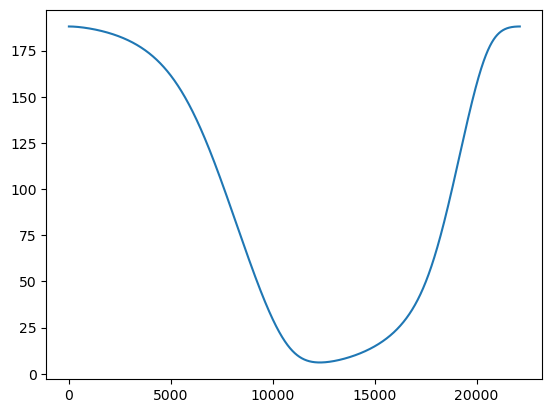

In [146]:
plt.plot(ref_cycle[:,18])

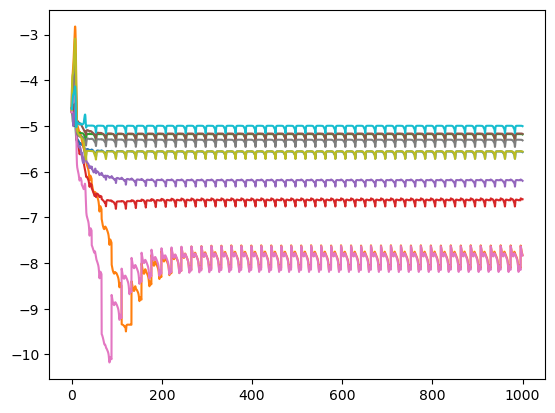

In [147]:
for n in range(1,11):
    plt.plot(t1_sub, all_logz[n])

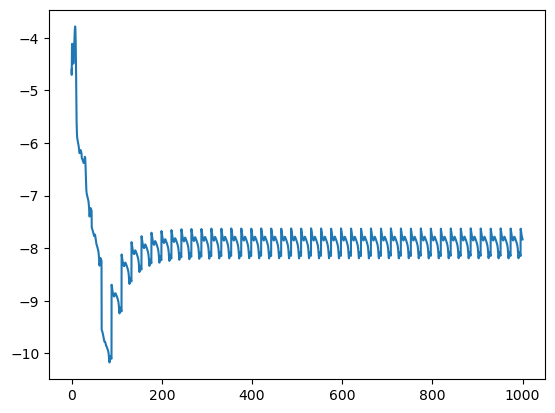

In [155]:
# plt.plot(t1_sub,r)
plt.plot(t1_sub, all_logz[7])
# plt.xlim(0,100)

In [185]:
def nearest_cycle_indices(X, ref_cycle):
    """
    For each state in X (N,d), return the index j of the nearest point on ref_cycle (M,d)
    and the corresponding Euclidean distance.
    """
    # brute-force O(NM) is fine for modest sizes; swap in a KDTree if M is large
    js = []
    ds = []
    for x in np.asarray(X):
        diffs = ref_cycle - x  # (M,d)
        d = np.linalg.norm(diffs, axis=1)
        j = int(np.argmin(d))
        js.append(j)
        ds.append(float(d[j]))
    return np.array(js, dtype=int), np.array(ds, dtype=float)


def plot_timecourse_projection(ref_cycle, X1_sub, t_ref=None, col=18, label_ref='ref', label_pts='X1_sub'):
    """
    Plot a *reference* time course (ref_cycle[:, col]) and overlay X1_sub points
    at the *time/phase* of their nearest point on the reference cycle.

    Parameters
    ----------
    ref_cycle : (M,d) array
    X1_sub    : (N,d) array
    t_ref     : (M,) array of times for the reference cycle; if None, uses [0..M-1]
    col       : column to plot (default 18)
    """
    ref_cycle = np.asarray(ref_cycle, float)
    X1_sub = np.asarray(X1_sub, float)
    M = ref_cycle.shape[0]
    if t_ref is None:
        t_ref = np.arange(M, dtype=float)
    else:
        t_ref = np.asarray(t_ref, float)

    # nearest-phase indices for each X1_sub point
    j_idx, _ = nearest_cycle_indices(X1_sub, ref_cycle)

    # project X1_sub onto those phase times
    t_proj = t_ref[j_idx]
    y_proj = X1_sub[:, col]

    fig = plt.figure(figsize=(8,4))
    plt.plot(t_ref, ref_cycle[:, col], lw=2, label=label_ref)
    plt.scatter(t_proj, y_proj, s=20, zorder=3, label=label_pts)
    plt.xlabel("Time / phase")
    plt.ylabel(f"Component {col}")
    plt.legend()
    plt.tight_layout()
    plt.show()

    


def plot_phase_convergence(ref_cycle, X1_sub, col_x=12, col_y=18, connect=True):
    """
    Phase diagram: ref_cycle[:, col_x] vs ref_cycle[:, col_y] as a closed curve,
    with X1_sub overlaid showing convergence toward the cycle. Optionally draw
    line segments from each X1_sub point to its nearest point on the cycle.

    Parameters
    ----------
    ref_cycle : (M,d)
    X1_sub    : (N,d)
    col_x, col_y : which components to plot on axes (defaults 12, 18)
    connect   : if True, draw small segments from X1_sub to the nearest ref point
    """
    ref_cycle = np.asarray(ref_cycle, float)
    X1_sub = np.asarray(X1_sub, float)

    # nearest-cycle index for each point
    j_idx, _ = nearest_cycle_indices(X1_sub, ref_cycle)

    # color X1_sub by time to show approach
    cmap = get_cmap('viridis')
    colors = cmap(np.linspace(0, 1, X1_sub.shape[0]))

    fig,ax = plt.subplots()
    # reference limit cycle
    ax.plot(ref_cycle[:, col_x], ref_cycle[:, col_y], lw=2, color='0.2', label='reference cycle')
    # perturbed trajectory samples
    ax.scatter(X1_sub[:, col_x], X1_sub[:, col_y], c=colors, s=15, label='X1_sub (early→late color)')

    if connect:
        # short connectors to nearest points on the cycle (visualizes shrinking gap)
        for k, j in enumerate(j_idx):
            x0, y0 = X1_sub[k, col_x], X1_sub[k, col_y]
            xc, yc = ref_cycle[j, col_x], ref_cycle[j, col_y]
            plt.plot([x0, xc], [y0, yc], color='r', lw=0.6, alpha=0.7)

    
    plt.xlabel(f"Component {col_x}")
    plt.ylabel(f"Component {col_y}")
    plt.legend(loc='best')
    plt.tight_layout()
    plt.show()

    return fig, ax

In [70]:
X1_sub.shape

(5001, 19)

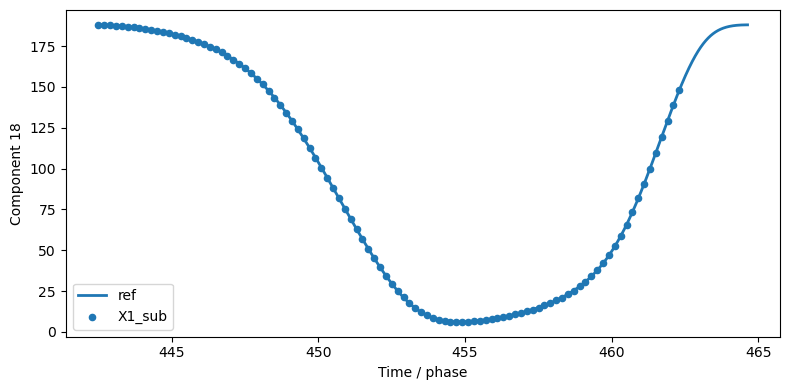

In [71]:
plot_timecourse_projection(ref_cycle, X1_sub[:100,:], t_ref=t_slice, col=18)


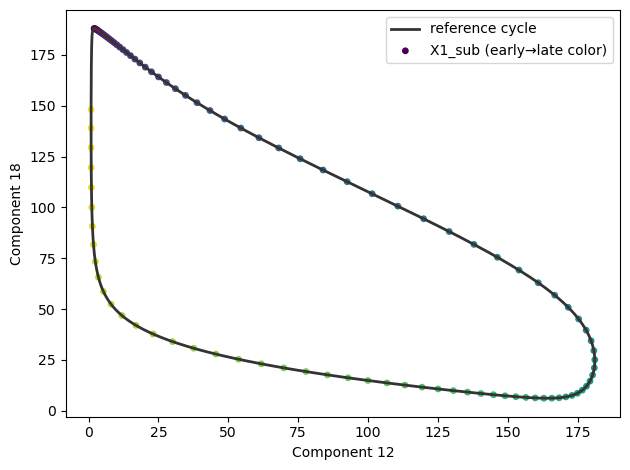

In [187]:
fig, ax = plot_phase_convergence(ref_cycle, X1_sub[:100,:], col_x=12, col_y=18, connect=True)



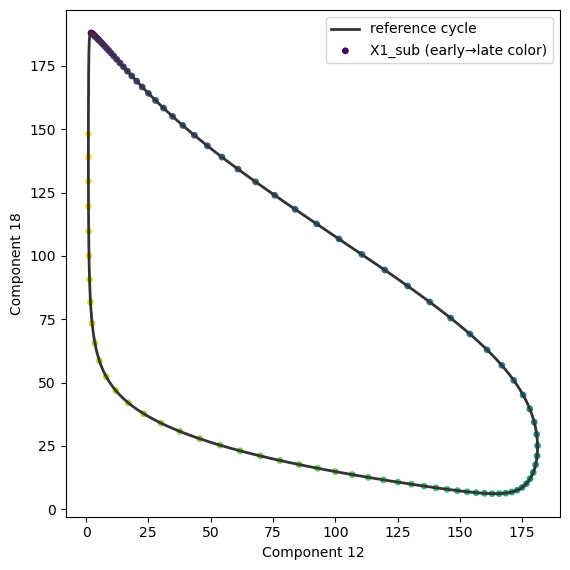

In [164]:
plot_phase_convergence(ref_cycle, X1_sub[:100,:], col_x=12, col_y=18, connect=True)

In [105]:
AKT = 0.6
ERK = 0.1
FAK = 0.616
model.parameters['AKT'].value = AKT
model.parameters['ERK'].value = ERK
model.parameters['FAK'].value = FAK
points = 10
verbose = True
ep = 0.001 * 200
t = np.linspace(0, 1000, 1000001)
t_0 = np.linspace(0, 2000, 2000001)
dt = t[1]-t[0]
all_logz = dict.fromkeys(list(range(1, points + 1)))

In [116]:
kk = 0
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python',
                            integrator_options=integrator_options).run()
y_out = sim_ode.observables

peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence=0.6, distance=10)
# new_y = y_out[peaks_cdc[-11]:peaks_cdc[-2]]
peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]
peaks_half2 = peaks_cdc[peaks_cdc > len(y_out) / 2]
names = y_out.dtype.names  

In [117]:
if len(peaks_half2) > 3:
    IMTs = [t[y] - t[x] for x, y in zip(peaks_half2, peaks_half2[1:])]
    meanIMT = sum(IMTs) / len(IMTs)
    stdIMT = np.std(IMTs)
    if stdIMT < 0.1:
        tmp_range = y_out[peaks_half[-3]:peaks_half[-2]]
        ref_cycle = np.column_stack([tmp_range[n] for n in names[:19]])
        t_slice = t[peaks_half[-3]:peaks_half[-2]]
        tmp_loc = (round(len(tmp_range) / (points)) * (kk))
    else:
        tmp_range = y_out[peaks_half[0]:peaks_half[-2]]
        ref_cycle = np.column_stack([tmp_range[n] for n in names[:19]])
        t_slice = t[peaks_half[0]:peaks_half[-2]]

        tmp_peak = y_out[peaks_half2[1]:peaks_half2[2]]
        tmp_loc = (round(len(tmp_peak) / (points)) * (kk))
else:
    meanIMT = 0
    tmp_range = y_out[575000:600000]
    ref_cycle = np.column_stack([tmp_range[n] for n in names[:19]])
    tmp_loc = (round(len(variable_range) / (points)) * (kk))
    t_slice = t[575000:600000]
if verbose:
    print(meanIMT)

ref_dcycle = finite_diff_loop(ref_cycle, t_slice)

for kk in range(points):
    row = tmp_range[tmp_loc]
    names19 = names[:19]
    x19 = np.array([row[n] for n in names19], float)
    
    # kick orthogonal to the tangent with preferred magnitude 0.01
    x19_pert, alpha_used = perturb_orthogonal_nonneg(
        x19, ref_cycle, ref_dcycle, magnitude=0.01
    )
    
    prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
             'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
             'Cdc20_0']
    prot_init = {prots[i]: float(x19_pert[i]) for i in range(len(prots))}
    
    # set initial conditions from first simulation
    for key in prot_init.keys():
        model.parameters[key].value = prot_init[key] / model.parameters['omega'].value
    
    # t1 = np.arange(0,t_slice[-1]-t_slice[0],dt)
    t1 = np.linspace(0, 1000, 1000001)
    sim_ode1 = ScipyOdeSimulator(model, t1, verbose=False, integrator_options=integrator_options).run()
    y_out1 = sim_ode1.observables
    X1 = np.column_stack([y_out1[n] for n in names[:19]])
    
    step = 200
    X1_sub = X1[::step]
    t1_sub = t1[::step]
    r = transverse_distance_series(X1_sub, ref_cycle, ref_dcycle)
    # log-distance series
    logz = np.log(np.maximum(r, 1e-300))
    all_logz[kk + 1] = logz.tolist()
    print(kk)

40.59918181818182
0
1
2
3
4
5
6
7
8
9


In [139]:
all_logz1=all_logz

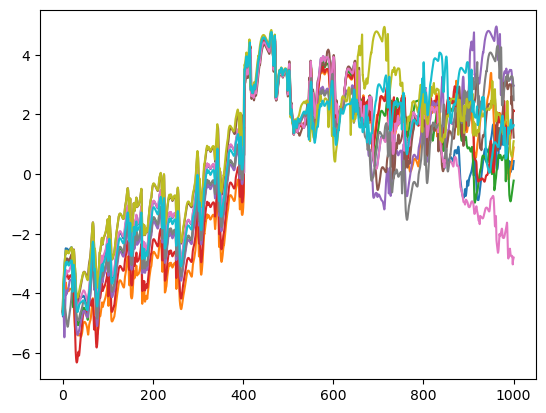

In [140]:
for n in range(1,11):
    plt.plot(t1_sub, all_logz1[n])

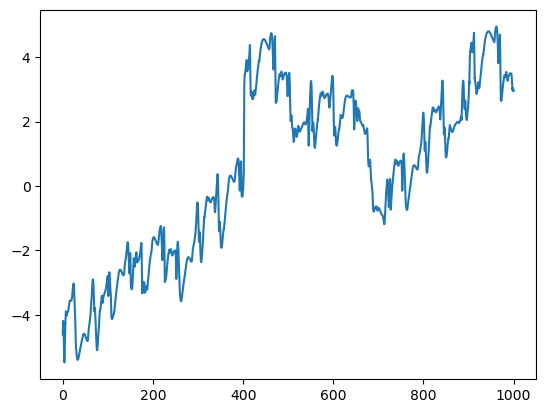

In [141]:
plt.plot(t1_sub, all_logz1[5])

In [32]:
step = 200
X1_sub = X1[::step]
t1_sub = t1[::step]
r = transverse_distance_series(X1_sub, ref_cycle, ref_dcycle)
# log-distance series for your downstream pipeline
logz = np.log(np.maximum(r, 1e-300))
# logz = np.log(r)
all_logz[kk + 1] = logz.tolist()

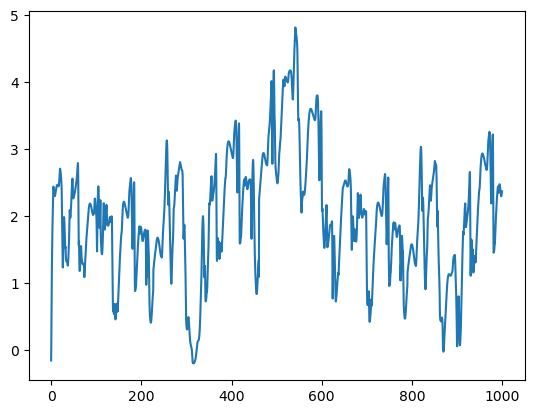

In [33]:
plt.plot(t1_sub,logz)
# plt.ylim(-20,5)

In [151]:
x=X1_sub[200]

In [152]:

# phase alignment: nearest point on reference cycle
j = np.argmin(np.linalg.norm(ref_cycle - x, axis=1))
v = ref_dcycle[j]
vhat = v / (np.linalg.norm(v) + 1e-12)
d = x - ref_cycle[j]
d_perp = d - np.dot(d, vhat) * vhat


In [153]:
d

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0.])

In [150]:
d_perp

array([-6.42608685e-02, -4.81414283e+00,  7.91245691e-01,  5.09788232e-01,
       -5.09788232e-01, -2.41078456e-13,  1.94662629e-01, -7.59388902e-01,
       -1.16123081e-01,  1.19563487e-01,  1.58213705e-02,  1.20235814e-02,
        4.83558776e-02,  4.44605266e-02,  7.57785971e-03, -2.68211223e-01,
        3.88474607e-02, -1.82450727e-01, -1.25570663e+00])

In [13]:
z = [0] * (round((len(y_out1) / 2000)) + 1)
n = 0
for i in range(0, len(y_out1), 2000):
    if len(peaks_half2) > 0:
        window = y_out[peaks_half[-3]+i+tmp_loc-5000:peaks_half[-2]+i+tmp_loc+5000]
    else:
        window = y_out[575000+i+tmp_loc-5000:600000+i+tmp_loc+5000]

    dists = [0] * len(window)
    for j in range(0, len(window)):
        dif = np.asarray(window[j].tolist())-np.asarray(y_out1[i].tolist())
        dists[j] = norm(dif[0:19]/200)

    z[n] = min(dists)
    n = n + 1

ValueError: min() arg is an empty sequence

In [14]:
z = [0] * (round((len(y_out1) / 2000)) + 1)
n = 0

In [15]:
i = 0
if len(peaks_half2) > 0:
    window = y_out[peaks_half[-3]+i+tmp_loc-5000:peaks_half[-2]+i+tmp_loc+5000]
else:
    window = y_out[575000+i+tmp_loc-5000:600000+i+tmp_loc+5000]

dists = [0] * len(window)
for j in range(0, len(window)):
    dif = np.asarray(window[j].tolist())-np.asarray(y_out1[i].tolist())
    dists[j] = norm(dif[0:19]/200)

z[n] = min(dists)
n = n + 1

In [16]:
min(dists)

0.004194395351461848

In [ ]:
plt.plot(z)

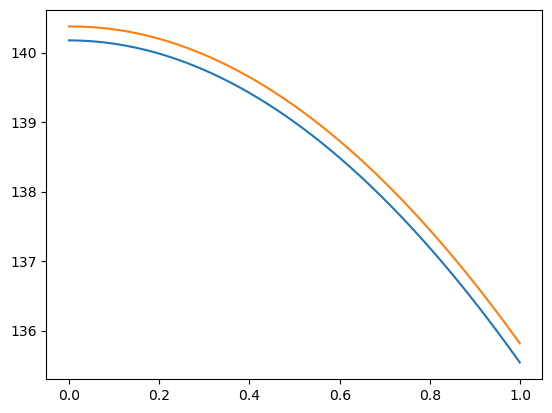

In [27]:
plt.plot(t[:1000],y_out1['obsCdc20'][:1000])
plt.plot(t[:1000],y_out2['obsCdc20'][:1000])

In [ ]:
# z = [0] * (round((len(y_out1) / 2000)) + 1)
# n = 0
# for i in range(0, len(y_out1), 2000):
#     if len(peaks_half2) > 0:
#         window = y_out[peaks_half[-3]+i+tmp_loc-5000:peaks_half[-2]+i+tmp_loc+5000]
#     else:
#         window = y_out[575000+i+tmp_loc-5000:600000+i+tmp_loc+5000]

#     dists = [0] * len(window)
#     for j in range(0, len(window)):
#         dif = np.asarray(window[j].tolist())-np.asarray(y_out1[i].tolist())
#         dists[j] = norm(dif[0:19]/200)

#     z[n] = min(dists)
#     n = n + 1

# logz = [math.log(num) for num in z]
# all_logz[kk + 1] = logz
# if verbose:
#     print([AKT, ERK, FAK, kk])

In [12]:
# def multiply(a, b):
#     return a * b

In [25]:
# pairs = [(random.random(),random.random()) for n in range(100000)]

In [ ]:
if __name__ == "__main__":
    from multiprocessing import Pool
    import time, numpy as np

    start = time.localtime()
    print(f'Start time is {time.strftime("%Y-%m-%d %H:%M:%S", start)}')

    with Pool(processes=PROCESSES) as p:
        results = p.starmap(run_lyaps, conds)
        for result in results:
            print(f'Appending result at {time.strftime("%Y-%m-%d %H:%M:%S", time.localtime())}')

    end = time.localtime()
    print(f'End time is {time.strftime("%Y-%m-%d %H:%M:%S", end)}')
    print(f'Process took {np.round((time.mktime(end) - time.mktime(start))/60, 2)} minutes')


Start time is 2025-07-01 10:55:19


In [ ]:
if __name__ ==  '__main__': 
    start = time.localtime()
    print(f'Start time is {time.strftime("%Y-%m-%d %H:%M:%S",start)}')
    results = []

    with mp.Pool(processes = PROCESSES) as p:

        results = p.starmap(run_lyaps, conds)
        # results = p.starmap(multiply, pairs)
    # for result in p.starmap(run_lyaps, conds):
    #     print(f'Appending result at {time.strftime("%Y-%m-%d %H:%M:%S",time.localtime())}')
    #     results.append(result)
    
    end = time.localtime()
    # print(results)
    print(f'End time is {time.strftime("%Y-%m-%d %H:%M:%S",end)}')
    print(f'Process took {np.round((time.mktime(end) - time.mktime(start))/60, 2)} minutes')

Start time is 2025-06-30 21:51:39


In [ ]:
if __name__ ==  '__main__': 
 num_processors = 3
 p=Pool(processes = num_processors)
 output = p.map(workers.worker,[i for i in range(0,3)])
 print(output)

In [11]:
start = time.time()
with mp.Pool(processes = PROCESSES) as p:
    results = p.starmap(run_lyaps, conds)
end = time.time()
print(end - start)

454.41411423683167


In [ ]:
model.parameters['AKT'].value = AKT
model.parameters['ERK'].value = ERK
model.parameters['FAK'].value = FAK
ep = 0.001 * 200
t = np.linspace(0, 1000, 1000001)
t_0 = np.linspace(0, 2000, 2000001)
all_logz = dict.fromkeys(list(range(1, points + 1)))

